In [5]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
df = pd.read_csv("sales_data_sample.csv", encoding="latin1")
df.head()


,ORDERNUMBER,QUANTITYORDERED,PRICEEACH,ORDERLINENUMBER,SALES,ORDERDATE,STATUS,QTR_ID,MONTH_ID,YEAR_ID,...,ADDRESSLINE1,ADDRESSLINE2,CITY,STATE,POSTALCODE,COUNTRY,TERRITORY,CONTACTLASTNAME,CONTACTFIRSTNAME,DEALSIZE
0,10107,30,95.70,2,2871.00,2/24/2003 0:00,Shipped,1,2,2003,...,897 Long Airport Avenue,NaN,NYC,NY,10022,USA,NaN,Yu,Kwai,Small
1,10121,34,81.35,5,2765.90,5/7/2003 0:00,Shipped,2,5,2003,...,59 rue de l'Abbaye,NaN,Reims,NaN,51100,France,EMEA,Henriot,Paul,Small
2,10134,41,94.74,2,3884.34,7/1/2003 0:00,Shipped,3,7,2003,...,27 rue du Colonel Pierre Avia,NaN,Paris,NaN,75508,France,EMEA,Da Cunha,Daniel,Medium
3,10145,45,83.26,6,3746.70,8/25/2003 0:00,Shipped,3,8,2003,...,78934 Hillside Dr.,NaN,Pasadena,CA,90003,USA,NaN,Young,Julie,Medium
4,10159,49,100.00,14,5205.27,10/10/2003 0:00,Shipped,4,10,2003,...,7734 Strong St.,NaN,San Francisco,CA,NaN,USA,NaN,Brown,Julie,Medium


In [7]:
df.shape

(2823, 25)

In [8]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 2823 entries, 0 to 2822
Data columns (total 25 columns):
 #   Column            Non-Null Count  Dtype  
---  ------            --------------  -----  
 0   ORDERNUMBER       2823 non-null   int64  
 1   QUANTITYORDERED   2823 non-null   int64  
 2   PRICEEACH         2823 non-null   float64
 3   ORDERLINENUMBER   2823 non-null   int64  
 4   SALES             2823 non-null   float64
 5   ORDERDATE         2823 non-null   object 
 6   STATUS            2823 non-null   object 
 7   QTR_ID            2823 non-null   int64  
 8   MONTH_ID          2823 non-null   int64  
 9   YEAR_ID           2823 non-null   int64  
 10  PRODUCTLINE       2823 non-null   object 
 11  MSRP              2823 non-null   int64  
 12  PRODUCTCODE       2823 non-null   object 
 13  CUSTOMERNAME      2823 non-null   object 
 14  PHONE             2823 non-null   object 
 15  ADDRESSLINE1      2823 non-null   object 
 16  ADDRESSLINE2      302 non-null    object 


In [9]:
df.isnull().sum()

,0
ORDERNUMBER,0
QUANTITYORDERED,0
PRICEEACH,0
ORDERLINENUMBER,0
SALES,0
ORDERDATE,0
STATUS,0
QTR_ID,0
MONTH_ID,0
YEAR_ID,0


In [11]:
df.duplicated().sum()

np.int64(0)

In [12]:
df.dtypes

,0
ORDERNUMBER,int64
QUANTITYORDERED,int64
PRICEEACH,float64
ORDERLINENUMBER,int64
SALES,float64
ORDERDATE,object
STATUS,object
QTR_ID,int64
MONTH_ID,int64
YEAR_ID,int64


In [13]:
df["ORDERDATE"] = pd.to_datetime(df["ORDERDATE"])

In [14]:
df["ORDERDATE"].dtype

dtype('<M8[ns]')

In [15]:
df[["ORDERDATE", "SALES"]].head()

,ORDERDATE,SALES
0,2003-02-24,2871.00
1,2003-05-07,2765.90
2,2003-07-01,3884.34
3,2003-08-25,3746.70
4,2003-10-10,5205.27


In [16]:
df.describe()

,ORDERNUMBER,QUANTITYORDERED,PRICEEACH,ORDERLINENUMBER,SALES,ORDERDATE,QTR_ID,MONTH_ID,YEAR_ID,MSRP
count,2823.000000,2823.000000,2823.000000,2823.000000,2823.000000,2823,2823.000000,2823.000000,2823.00000,2823.000000
mean,10258.725115,35.092809,83.658544,6.466171,3553.889072,2004-05-11 00:16:49.989373056,2.717676,7.092455,2003.81509,100.715551
min,10100.000000,6.000000,26.880000,1.000000,482.130000,2003-01-06 00:00:00,1.000000,1.000000,2003.00000,33.000000
25%,10180.000000,27.000000,68.860000,3.000000,2203.430000,2003-11-06 12:00:00,2.000000,4.000000,2003.00000,68.000000
50%,10262.000000,35.000000,95.700000,6.000000,3184.800000,2004-06-15 00:00:00,3.000000,8.000000,2004.00000,99.000000
75%,10333.500000,43.000000,100.000000,9.000000,4508.000000,2004-11-17 12:00:00,4.000000,11.000000,2004.00000,124.000000
max,10425.000000,97.000000,100.000000,18.000000,14082.800000,2005-05-31 00:00:00,4.000000,12.000000,2005.00000,214.000000
std,92.085478,9.741443,20.174277,4.225841,1841.865106,NaN,1.203878,3.656633,0.69967,40.187912


In [17]:
(df["SALES"] <= 0).sum()

np.int64(0)

In [18]:
df[["ORDERDATE", "SALES", "PRODUCTLINE",
    "COUNTRY", "CUSTOMERNAME"]].isnull().sum()

,0
ORDERDATE,0
SALES,0
PRODUCTLINE,0
COUNTRY,0
CUSTOMERNAME,0


In [19]:
df["ORDERDATE"].min(), df["ORDERDATE"].max()

(Timestamp('2003-01-06 00:00:00'), Timestamp('2005-05-31 00:00:00'))

In [20]:
product_sales = (
    df.groupby("PRODUCTLINE")["SALES"]
      .sum()
      .sort_values(ascending=False)
)

product_sales

,SALES
PRODUCTLINE,
Classic Cars,3919615.66
Vintage Cars,1903150.84
Motorcycles,1166388.34
Trucks and Buses,1127789.84
Planes,975003.57
Ships,714437.13
Trains,226243.47


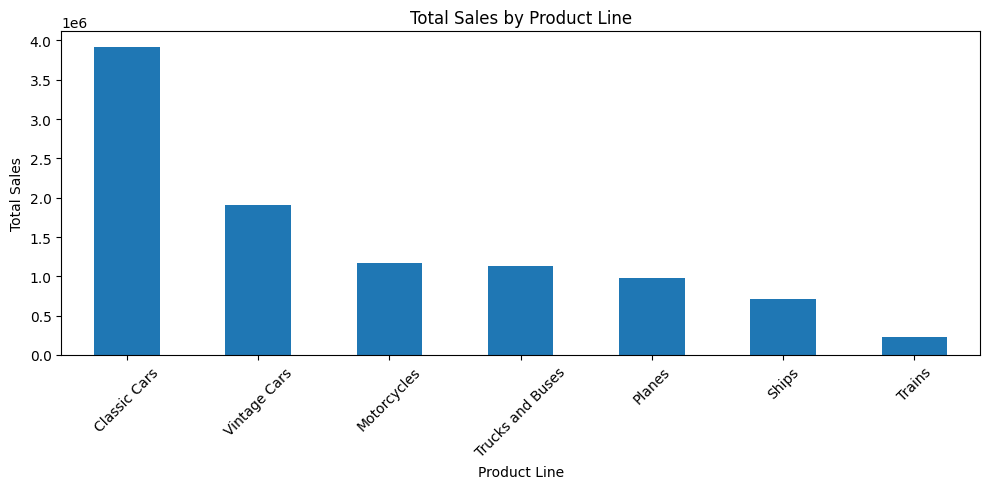

In [21]:
plt.figure(figsize=(10, 5))

product_sales.plot(kind="bar")

plt.title("Total Sales by Product Line")
plt.xlabel("Product Line")
plt.ylabel("Total Sales")
plt.xticks(rotation=45)
plt.tight_layout()

plt.show()

In [22]:
monthly_sales = (
    df.groupby(df["ORDERDATE"].dt.to_period("M"))["SALES"]
      .sum()
)

monthly_sales

,SALES
ORDERDATE,
2003-01,129753.60
2003-02,140836.19
2003-03,174504.90
2003-04,201609.55
2003-05,192673.11
2003-06,168082.56
2003-07,187731.88
2003-08,197809.30
2003-09,263973.36


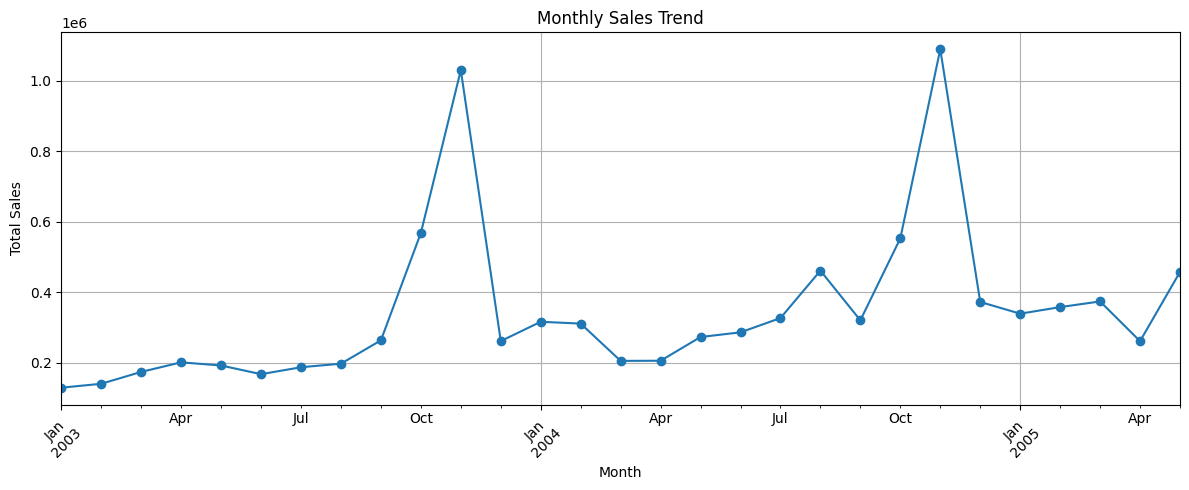

In [23]:
plt.figure(figsize=(12, 5))

monthly_sales.plot(kind="line", marker="o")

plt.title("Monthly Sales Trend")
plt.xlabel("Month")
plt.ylabel("Total Sales")
plt.xticks(rotation=45)
plt.grid(True)
plt.tight_layout()

plt.show()

In [24]:
country_sales = (
    df.groupby("COUNTRY")["SALES"]
      .sum()
      .sort_values(ascending=False)
)

country_sales.head(10)

,SALES
COUNTRY,
USA,3627982.83
Spain,1215686.92
France,1110916.52
Australia,630623.10
UK,478880.46
Italy,374674.31
Finland,329581.91
Norway,307463.70
Singapore,288488.41


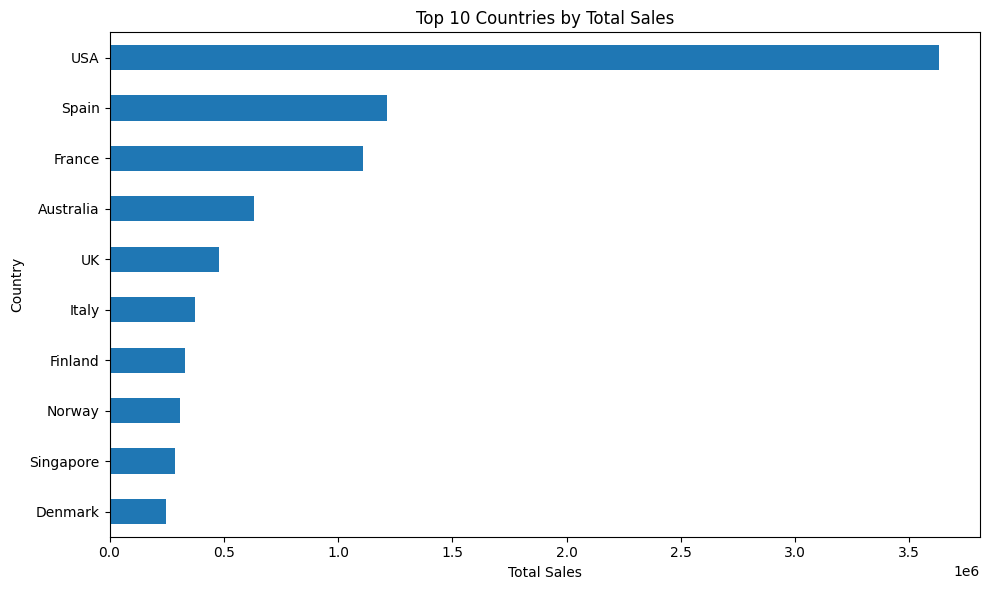

In [25]:
plt.figure(figsize=(10, 6))

country_sales.head(10).sort_values().plot(kind="barh")

plt.title("Top 10 Countries by Total Sales")
plt.xlabel("Total Sales")
plt.ylabel("Country")
plt.tight_layout()

plt.show()

In [26]:
quantity_by_product = (
    df.groupby("PRODUCTLINE")["QUANTITYORDERED"]
      .sum()
      .sort_values(ascending=False)
)

quantity_by_product

,QUANTITYORDERED
PRODUCTLINE,
Classic Cars,33992
Vintage Cars,21069
Motorcycles,11663
Trucks and Buses,10777
Planes,10727
Ships,8127
Trains,2712


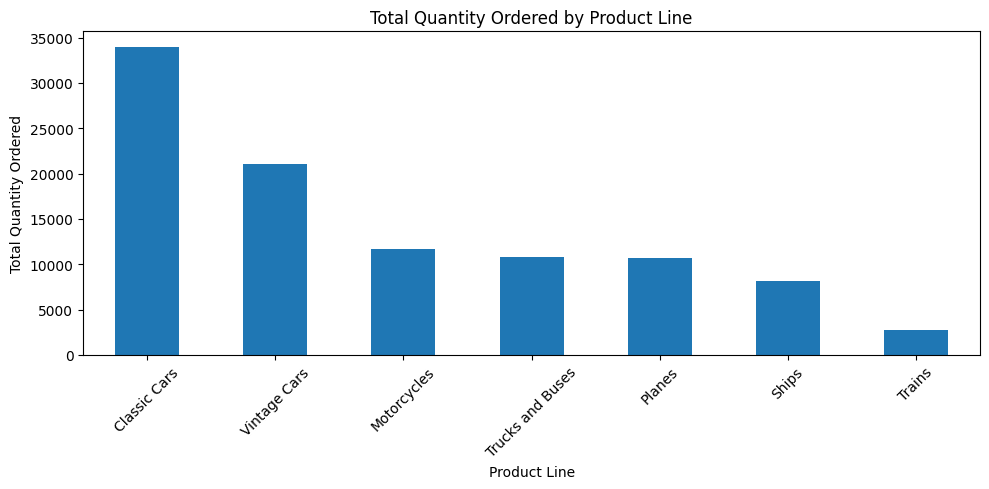

In [27]:
plt.figure(figsize=(10, 5))

quantity_by_product.plot(kind="bar")

plt.title("Total Quantity Ordered by Product Line")
plt.xlabel("Product Line")
plt.ylabel("Total Quantity Ordered")
plt.xticks(rotation=45)
plt.tight_layout()

plt.show()

In [28]:
deal_sales = (
    df.groupby("DEALSIZE")["SALES"]
      .sum()
      .sort_values(ascending=False)
)

deal_sales

,SALES
DEALSIZE,
Medium,6087432.24
Small,2643077.35
Large,1302119.26


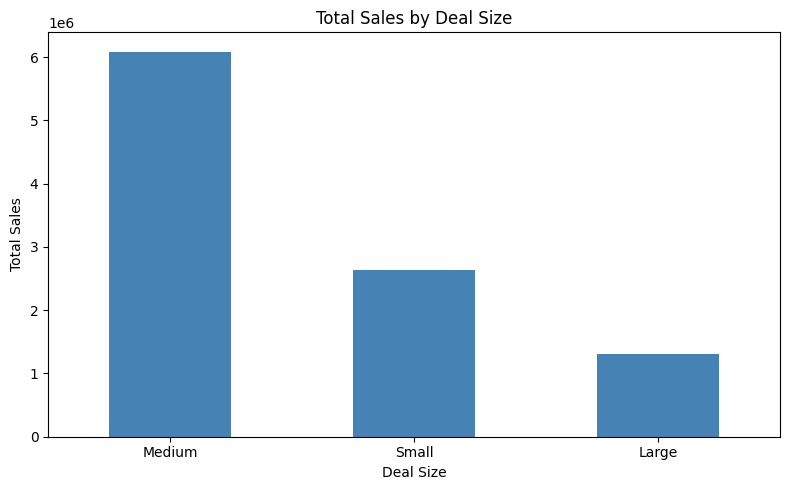

In [29]:
plt.figure(figsize=(8, 5))

deal_sales.plot(kind="bar", color="steelblue")

plt.title("Total Sales by Deal Size")
plt.xlabel("Deal Size")
plt.ylabel("Total Sales")
plt.xticks(rotation=0)
plt.tight_layout()

plt.show()

In [30]:
customer_sales = (
    df.groupby("CUSTOMERNAME")["SALES"]
      .sum()
      .sort_values(ascending=False)
)

customer_sales.head(10)

,SALES
CUSTOMERNAME,
Euro Shopping Channel,912294.11
Mini Gifts Distributors Ltd.,654858.06
"Australian Collectors, Co.",200995.41
Muscle Machine Inc,197736.94
La Rochelle Gifts,180124.90
"Dragon Souveniers, Ltd.",172989.68
Land of Toys Inc.,164069.44
The Sharp Gifts Warehouse,160010.27
"AV Stores, Co.",157807.81


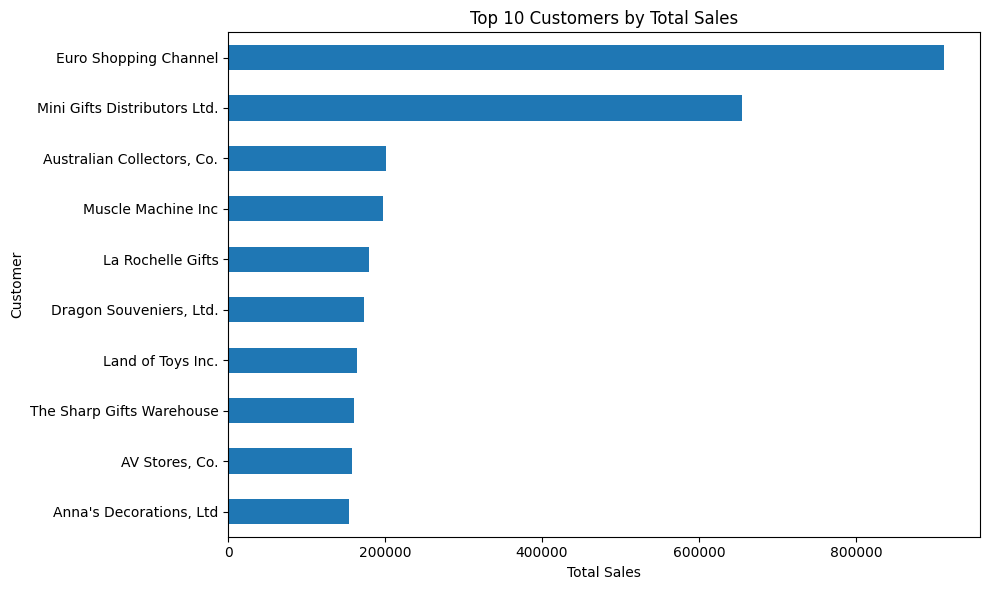

In [31]:
plt.figure(figsize=(10, 6))

customer_sales.head(10).sort_values().plot(kind="barh")

plt.title("Top 10 Customers by Total Sales")
plt.xlabel("Total Sales")
plt.ylabel("Customer")
plt.tight_layout()

plt.show()

In [32]:
numeric_df = df[
    ["SALES", "QUANTITYORDERED", "PRICEEACH"]
]

In [33]:
correlation = numeric_df.corr()

correlation

,SALES,QUANTITYORDERED,PRICEEACH
SALES,1.000000,0.551426,0.657841
QUANTITYORDERED,0.551426,1.000000,0.005564
PRICEEACH,0.657841,0.005564,1.000000


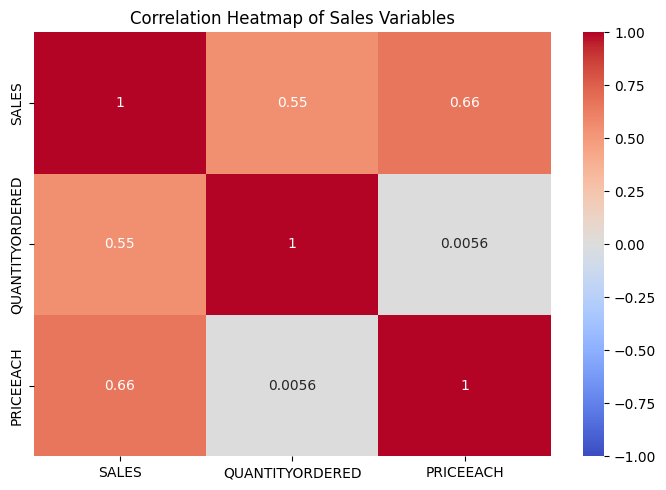

In [34]:
plt.figure(figsize=(7, 5))

sns.heatmap(
    correlation,
    annot=True,
    cmap="coolwarm",
    vmin=-1,
    vmax=1
)

plt.title("Correlation Heatmap of Sales Variables")
plt.tight_layout()
plt.show()

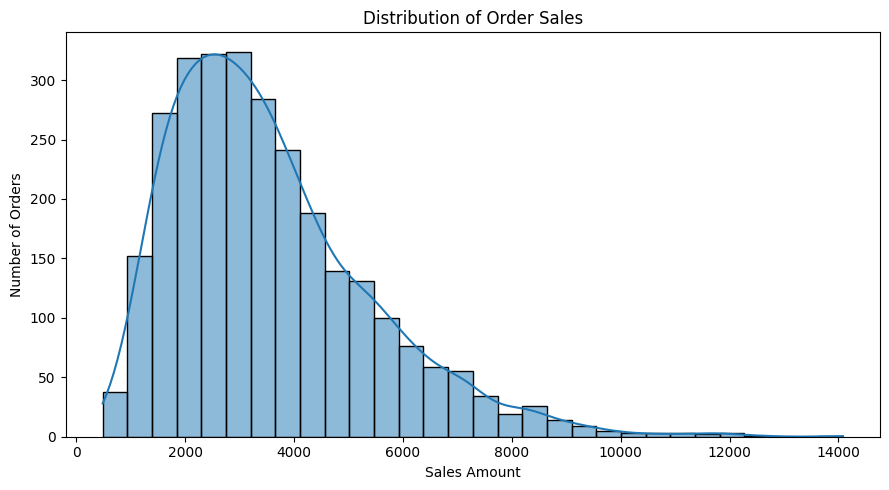

In [35]:
plt.figure(figsize=(9, 5))

sns.histplot(data=df, x="SALES", bins=30, kde=True)

plt.title("Distribution of Order Sales")
plt.xlabel("Sales Amount")
plt.ylabel("Number of Orders")

plt.tight_layout()
plt.show()

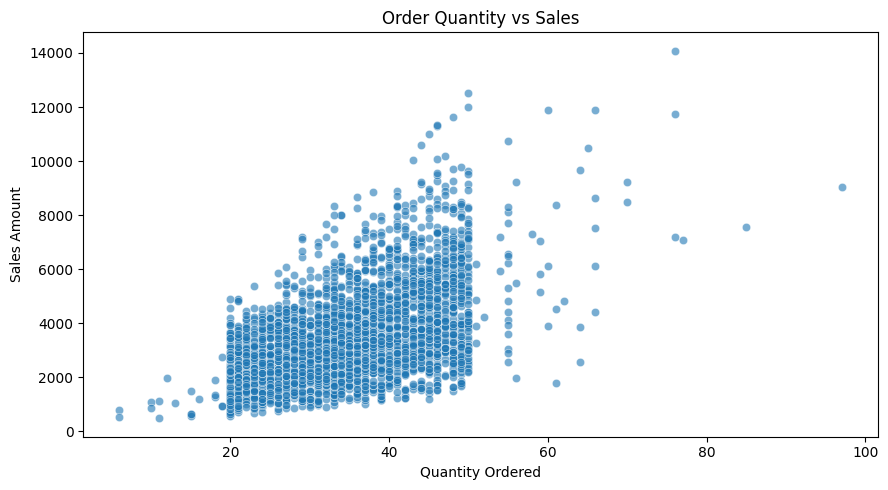

In [36]:
plt.figure(figsize=(9, 5))

sns.scatterplot(
    data=df,
    x="QUANTITYORDERED",
    y="SALES",
    alpha=0.6
)

plt.title("Order Quantity vs Sales")
plt.xlabel("Quantity Ordered")
plt.ylabel("Sales Amount")

plt.tight_layout()
plt.show()

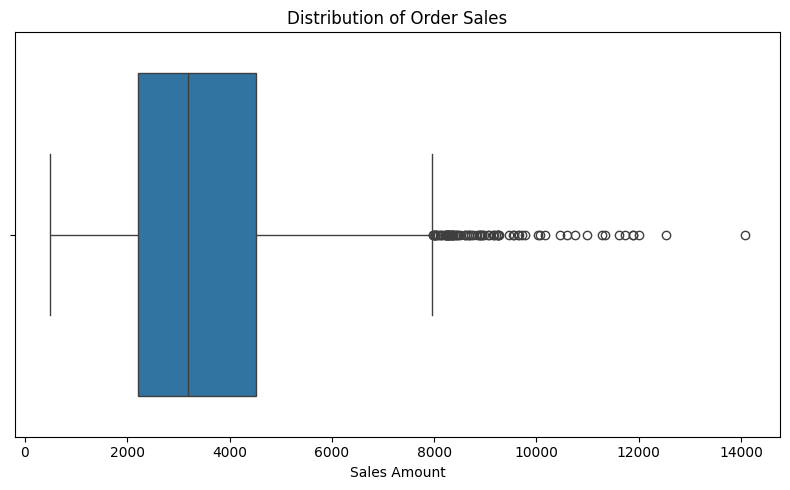

In [37]:
plt.figure(figsize=(8, 5))

sns.boxplot(data=df, x="SALES")

plt.title("Distribution of Order Sales")
plt.xlabel("Sales Amount")

plt.tight_layout()
plt.show()

In [38]:
total_sales = df["SALES"].sum()
total_orders = df["ORDERNUMBER"].nunique()
total_customers = df["CUSTOMERNAME"].nunique()
average_order_sales = df.groupby("ORDERNUMBER")["SALES"].sum().mean()

print("Total Sales:", round(total_sales, 2))
print("Total Orders:", total_orders)
print("Total Customers:", total_customers)
print("Average Sales per Order:", round(average_order_sales, 2))

Total Sales: 10032628.85
Total Orders: 307
Total Customers: 92
Average Sales per Order: 32679.57


In [39]:
product_summary = (
    df.groupby("PRODUCTLINE")
      .agg(
          Total_Sales=("SALES", "sum"),
          Total_Quantity=("QUANTITYORDERED", "sum")
      )
      .sort_values("Total_Sales", ascending=False)
)

product_summary

,Total_Sales,Total_Quantity
PRODUCTLINE,,
Classic Cars,3919615.66,33992
Vintage Cars,1903150.84,21069
Motorcycles,1166388.34,11663
Trucks and Buses,1127789.84,10777
Planes,975003.57,10727
Ships,714437.13,8127
Trains,226243.47,2712


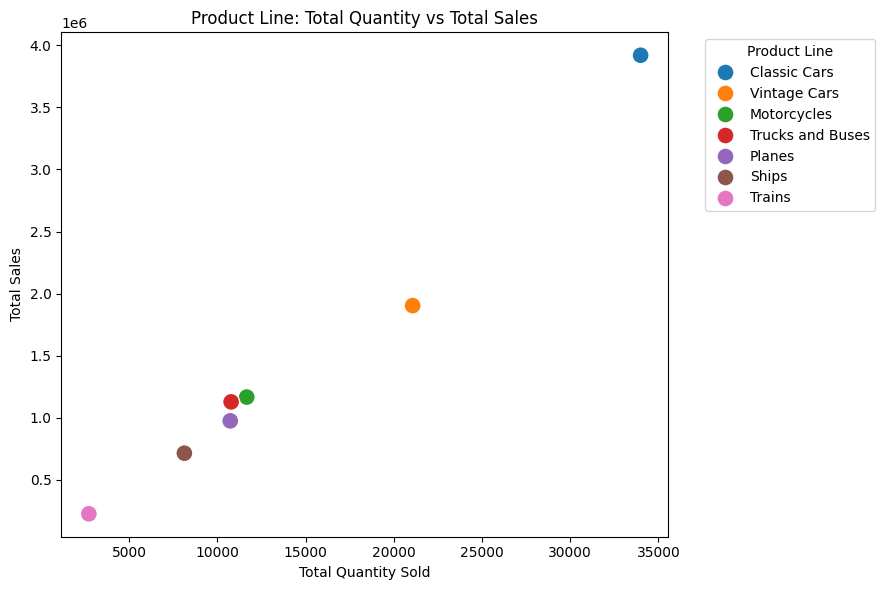

In [40]:
plt.figure(figsize=(9, 6))

sns.scatterplot(
    data=product_summary,
    x="Total_Quantity",
    y="Total_Sales",
    hue=product_summary.index,
    s=150
)

plt.title("Product Line: Total Quantity vs Total Sales")
plt.xlabel("Total Quantity Sold")
plt.ylabel("Total Sales")
plt.legend(title="Product Line", bbox_to_anchor=(1.05, 1))
plt.tight_layout()
plt.show()